# UTS Intelegensi Buatan — Kasus 1: Klasifikasi Kultivar Anggur

| | |
|---|---|
| **Mata kuliah** | Intelegensi Buatan (3 SKS) · TIF RM 23 A |
| **Dosen** | Muhammad Ikhwan Fathulloh, S.Kom. |
| **Nama** | Muhammad Daffa Syahbaa F.P.N |
| **NIM** | 24552011326 |
| **Dataset / target** | `kasus01_wine.csv` / `kultivar` (Kultivar A, B, C) |

Notebook ini menjalankan **seluruh alur** secara berurutan: audit data → feature engineering → perbandingan model → evaluasi → penyimpanan joblib → aplikasi Streamlit.
Pilih **Runtime → Run all**; sel terakhir mencetak tautan aplikasi Streamlit.

**Alur dan kepatuhan aturan UTS**

1. Data dibagi train/test (stratified 80/20) **sebelum** imputasi, scaling, atau fitur apa pun.
2. Semua statistik preprocessing berada di dalam `Pipeline` sehingga hanya dipelajari dari data train.
3. Pemilihan fitur dan model memakai *cross-validation* di data train (nested CV); data test dipakai **satu kali**.
4. Pipeline + metadata disimpan di `models/wine_kultivar.joblib`; tidak ada kredensial atau path absolut.

## 0. Persiapan lingkungan

In [1]:
!pip install -q streamlit
import os, sys, warnings
warnings.filterwarnings("ignore")
os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)
sys.path.insert(0, os.getcwd())
print("Python", sys.version.split()[0])

Python 3.13.18


## 1. Menulis modul proyek
Tiga sel berikut menuliskan `fitur.py` (feature engineering), `latih.py` (pelatihan, evaluasi, simpan model), dan `app.py` (aplikasi Streamlit) ke direktori kerja Colab.
Isinya identik dengan file pada repositori.

In [2]:
%%writefile fitur.py
"""
fitur.py - Feature engineering untuk Kasus 1: Klasifikasi kultivar anggur.

Isi modul:
  * muat_data()      : membaca dataset (lokal -> unduh GitHub -> cadangan scikit-learn)
  * bersihkan()      : pembersihan dasar (duplikat, target kosong, nilai tidak wajar)
  * audit_data()     : audit data (duplikat, missing, tipe data, outlier, korelasi)
  * FiturRasio       : transformer scikit-learn untuk fitur rasio (stateless, aman dari
                       kebocoran data karena tidak menghitung statistik apa pun)
  * buat_pipeline()  : pipeline lengkap  imputasi -> fitur rasio -> scaling -> model

Semua statistik preprocessing (median imputasi, mean/std scaler) dipelajari HANYA dari
data train karena berada di dalam Pipeline yang di-fit pada data train.
"""
from __future__ import annotations

import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
BASE_DIR = Path(__file__).resolve().parent
NAMA_FILE = "kasus01_wine.csv"
TARGET = "kultivar"

URL_DATASET = [
    "https://raw.githubusercontent.com/Muhammad-Ikhwan-Fathulloh/"
    "Artificial-Intelegent-Course-Bank/main/UTS/dataset/" + NAMA_FILE,
    "https://raw.githubusercontent.com/Muhammad-Ikhwan-Fathulloh/"
    "ArtificialIntelegent-Course-Bank/main/UTS/dataset/" + NAMA_FILE,
]

# 13 komponen kimia anggur (fitur mentah) beserta metadata untuk antarmuka aplikasi
INFO_FITUR = {
    "alcohol": ("Alkohol", "% vol", "Kadar alkohol", 0.01, "%.2f"),
    "malic_acid": ("Asam malat", "g/L", "Kadar asam malat", 0.01, "%.2f"),
    "ash": ("Abu (ash)", "g/L", "Kadar abu", 0.01, "%.2f"),
    "alcalinity_of_ash": ("Alkalinitas abu", "", "Alkalinitas abu", 0.1, "%.1f"),
    "magnesium": ("Magnesium", "mg/L", "Kadar magnesium", 1.0, "%.0f"),
    "total_phenols": ("Total fenol", "", "Total komponen fenolik", 0.01, "%.2f"),
    "flavanoids": ("Flavonoid", "", "Fenol jenis flavonoid", 0.01, "%.2f"),
    "nonflavanoid_phenols": ("Fenol nonflavonoid", "", "Fenol non-flavonoid", 0.01, "%.2f"),
    "proanthocyanins": ("Proantosianin", "", "Proantosianin", 0.01, "%.2f"),
    "color_intensity": ("Intensitas warna", "", "Intensitas warna anggur", 0.01, "%.2f"),
    "hue": ("Hue (rona)", "", "Rona warna anggur", 0.01, "%.2f"),
    "od280_od315_of_diluted_wines": (
        "OD280/OD315", "", "Rasio absorbansi anggur terencerkan", 0.01, "%.2f"),
    "proline": ("Prolin", "mg/L", "Kadar prolin", 1.0, "%.0f"),
}
FITUR_ASLI = list(INFO_FITUR.keys())

# Fitur rasio: pasangan fitur yang saling terkait secara kimia
# nama_fitur_baru: (pembilang, penyebut, alasan)
RASIO = {
    "rasio_flavonoid_fenol": ("flavanoids", "total_phenols",
                              "porsi flavonoid dalam total fenol"),
    "rasio_nonflavonoid_fenol": ("nonflavanoid_phenols", "total_phenols",
                                 "porsi fenol nonflavonoid dalam total fenol"),
    "rasio_proantosianin_fenol": ("proanthocyanins", "total_phenols",
                                  "porsi proantosianin dalam total fenol"),
    "rasio_od_flavonoid": ("od280_od315_of_diluted_wines", "flavanoids",
                           "absorbansi per satuan flavonoid"),
    "rasio_alkalinitas_abu": ("alcalinity_of_ash", "ash",
                              "alkalinitas relatif terhadap kadar abu"),
    "rasio_prolin_alkohol": ("proline", "alcohol",
                             "prolin relatif terhadap kadar alkohol"),
}

# Varian fitur yang dibandingkan pada tahap ablasi (dipilih dengan CV di data train)
VARIAN_FITUR = {
    "A. Fitur asli saja (13)": dict(tambah_rasio=False, buang=()),
    "B. Asli + rasio (19)": dict(tambah_rasio=True, buang=()),
    "C. Rasio, tanpa total_phenols & flavanoids (17)": dict(
        tambah_rasio=True, buang=("total_phenols", "flavanoids")),
}


# ----------------------------------------------------------------------------------
# Pemuatan dan pembersihan data
# ----------------------------------------------------------------------------------
def normalisasi_kolom(nama: str) -> str:
    """Samakan format nama kolom: huruf kecil, spasi dan '/' menjadi '_'."""
    nama = str(nama).strip().lower()
    nama = re.sub(r"[\s/\-\.]+", "_", nama)
    return re.sub(r"_+", "_", nama).strip("_")


def _rapikan(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [normalisasi_kolom(c) for c in df.columns]
    # buang kolom indeks bawaan jika ada
    df = df.drop(columns=[c for c in df.columns if c.startswith("unnamed")], errors="ignore")
    if TARGET not in df.columns:
        for alt in ("target", "class", "cultivar", "kelas"):
            if alt in df.columns:
                df = df.rename(columns={alt: TARGET})
                break
    if TARGET in df.columns and pd.api.types.is_numeric_dtype(df[TARGET]):
        nilai = sorted(df[TARGET].dropna().unique())
        huruf = "ABC"
        df[TARGET] = df[TARGET].map({v: f"Kultivar {huruf[i]}" for i, v in enumerate(nilai)})
    elif TARGET in df.columns:
        df[TARGET] = df[TARGET].astype(str).str.strip()
    return df


def _cadangan_sklearn() -> pd.DataFrame:
    from sklearn.datasets import load_wine

    d = load_wine(as_frame=True).frame
    d["target"] = d["target"].map({0: "Kultivar A", 1: "Kultivar B", 2: "Kultivar C"})
    return d.rename(columns={"target": TARGET})


def muat_data(path: str | Path | None = None, verbose: bool = True) -> pd.DataFrame:
    """Baca dataset. Urutan: path eksplisit -> dataset/ -> unduh GitHub -> cadangan sklearn."""
    kandidat = [Path(path)] if path else []
    kandidat += [BASE_DIR / "dataset" / NAMA_FILE, Path("dataset") / NAMA_FILE, Path(NAMA_FILE)]
    for p in kandidat:
        if p.exists():
            if verbose:
                print(f"[data] membaca {p.name} dari {p.parent.name or '.'}/")
            return _rapikan(pd.read_csv(p))
    tujuan = BASE_DIR / "dataset" / NAMA_FILE
    for url in URL_DATASET:
        try:
            tujuan.parent.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(url, tujuan)
            if verbose:
                print("[data] berhasil diunduh dari repositori mata kuliah")
            return _rapikan(pd.read_csv(tujuan))
        except Exception:  # noqa: BLE001 - jaringan bisa gagal dengan berbagai cara
            continue
    if verbose:
        print("[data] PERINGATAN: file tidak ditemukan; memakai Wine dataset dari scikit-learn "
              "(data UCI yang sama, 178 sampel).")
    return _rapikan(_cadangan_sklearn())


def bersihkan(df: pd.DataFrame) -> pd.DataFrame:
    """Pembersihan dasar yang tidak menghitung statistik apa pun (aman sebelum split).

    * hapus baris duplikat dan baris tanpa target
    * nilai <= 0 pada fitur kimia dianggap tidak wajar -> NaN (diimputasi di dalam pipeline)
    """
    df = _rapikan(df).drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)
    for kol in FITUR_ASLI:
        df[kol] = pd.to_numeric(df[kol], errors="coerce")
        df.loc[df[kol] <= 0, kol] = np.nan
    return df[FITUR_ASLI + [TARGET]]


def audit_data(df: pd.DataFrame, ambang_korelasi: float = 0.6) -> dict:
    """Audit data: bentuk, duplikat, missing, tipe, nilai tidak wajar, outlier IQR, korelasi."""
    df = _rapikan(df)
    fitur = df[FITUR_ASLI]
    q1, q3 = fitur.quantile(0.25), fitur.quantile(0.75)
    iqr = q3 - q1
    outlier = ((fitur < q1 - 1.5 * iqr) | (fitur > q3 + 1.5 * iqr)).sum()
    kor = fitur.corr()
    pasangan = (
        kor.where(np.triu(np.ones(kor.shape), 1).astype(bool))
        .stack()
        .rename("korelasi")
        .reset_index()
        .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"})
    )
    tinggi = pasangan[pasangan["korelasi"].abs() >= ambang_korelasi].sort_values(
        "korelasi", key=abs, ascending=False)
    return {
        "jumlah_baris": int(len(df)),
        "jumlah_kolom": int(df.shape[1]),
        "duplikat": int(df.duplicated().sum()),
        "missing_total": int(df.isna().sum().sum()),
        "missing_per_kolom": df.isna().sum()[lambda s: s > 0].to_dict(),
        "tipe_data": {k: str(v) for k, v in df.dtypes.items()},
        "nilai_tidak_wajar_<=0": int((fitur <= 0).sum().sum()),
        "outlier_iqr": outlier[outlier > 0].to_dict(),
        "distribusi_kelas": df[TARGET].value_counts().to_dict(),
        "korelasi_tinggi": tinggi.round(3).to_dict("records"),
        "statistik": df[FITUR_ASLI].describe().T.round(3),
    }


# ----------------------------------------------------------------------------------
# Transformer fitur rasio
# ----------------------------------------------------------------------------------
class FiturRasio(BaseEstimator, TransformerMixin):
    """Menambah fitur rasio dan (opsional) membuang kolom asli.

    Transformer ini *stateless*: rasio dihitung baris demi baris sehingga tidak ada
    informasi dari data test yang masuk ke data train (tidak ada kebocoran data).
    """

    def __init__(self, tambah_rasio: bool = True, buang: tuple = ()):
        self.tambah_rasio = tambah_rasio
        self.buang = buang

    def fit(self, X, y=None):
        self.feature_names_in_ = np.array(
            list(X.columns) if isinstance(X, pd.DataFrame) else FITUR_ASLI)
        return self

    def transform(self, X):
        df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_)
        if self.tambah_rasio:
            for nama, (atas, bawah, _) in RASIO.items():
                df[nama] = df[atas] / df[bawah].clip(lower=1e-9)
        if self.buang:
            df = df.drop(columns=list(self.buang))
        return df

    def get_feature_names_out(self, input_features=None):
        return np.array(self.transform(pd.DataFrame(
            np.ones((1, len(self.feature_names_in_))), columns=self.feature_names_in_)).columns)


# ----------------------------------------------------------------------------------
# Pipeline
# ----------------------------------------------------------------------------------
def buat_model(nama: str):
    """Daftar algoritma yang dibandingkan."""
    if nama == "Logistic Regression":
        return LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_STATE)
    if nama == "SVM (RBF)":
        return SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE)
    if nama == "KNN":
        return KNeighborsClassifier(n_neighbors=5)
    if nama == "Random Forest":
        return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
    if nama == "Gradient Boosting":
        return GradientBoostingClassifier(random_state=RANDOM_STATE)
    raise ValueError(f"Model tidak dikenal: {nama}")


NAMA_MODEL = ["Logistic Regression", "SVM (RBF)", "KNN", "Random Forest", "Gradient Boosting"]


def buat_pipeline(nama_model: str, tambah_rasio: bool = True, buang: tuple = ()) -> Pipeline:
    """imputasi median -> fitur rasio -> StandardScaler -> model.

    Scaler dipasang pada SEMUA model agar perbandingan konsisten; untuk model berbasis
    pohon scaling tidak mengubah hasil, tetapi untuk LR/SVM/KNN scaling wajib karena
    skala fitur sangat berbeda (proline ~ ratusan-ribuan, hue ~ 0,5-1,7).
    """
    imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
    return Pipeline([
        ("imputasi", imputer),
        ("fitur", FiturRasio(tambah_rasio=tambah_rasio, buang=tuple(buang))),
        ("scaling", StandardScaler()),
        ("model", buat_model(nama_model)),
    ])


GRID_TUNING = {
    "Logistic Regression": {"model__C": [0.1, 1.0, 10.0]},
    "SVM (RBF)": {"model__C": [1.0, 10.0], "model__gamma": ["scale", 0.01]},
    "KNN": {"model__n_neighbors": [3, 5, 9], "model__weights": ["uniform", "distance"]},
    "Random Forest": {"model__max_depth": [None, 5], "model__min_samples_leaf": [1, 2]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__max_depth": [2, 3]},
}

Writing fitur.py


In [3]:
%%writefile latih.py
"""
latih.py - Pelatihan, evaluasi, dan penyimpanan model Kasus 1 (kultivar anggur).

Alur (sesuai aturan UTS):
  1. Muat data, audit, bersihkan (tanpa menghitung statistik apa pun).
  2. SPLIT train/test (stratified 80/20) SEBELUM imputasi, scaling, atau encoding.
  3. Pilih varian fitur dan algoritma dengan cross-validation HANYA di data train
     (ablasi fitur + nested CV: tuning di loop dalam, estimasi di loop luar).
  4. Latih model terpilih pada seluruh data train, evaluasi pada data test SATU KALI.
  5. Simpan pipeline + metadata ke models/wine_kultivar.joblib dan metrik ke JSON.

Jalankan:  python latih.py
"""
from __future__ import annotations

import json
import platform
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, log_loss, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, train_test_split)

import fitur as F

warnings.filterwarnings("ignore")

BASE_DIR = Path(__file__).resolve().parent
DIR_MODEL = BASE_DIR / "models"
DIR_FIGUR = DIR_MODEL / "figures"
FILE_MODEL = DIR_MODEL / "wine_kultivar.joblib"
TEST_SIZE = 0.2
RS = F.RANDOM_STATE


def wilson(benar: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """Interval kepercayaan 95% (Wilson) untuk akurasi."""
    p = benar / n
    pusat = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    lebar = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return float(pusat - lebar), float(min(1.0, pusat + lebar))


def hitung_metrik(y_true, y_pred, proba, kelas) -> dict:
    """Metrik klasifikasi multikelas pada data test."""
    cm = confusion_matrix(y_true, y_pred, labels=kelas)
    lo, hi = wilson(int((np.array(y_true) == np.array(y_pred)).sum()), len(y_true))
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "accuracy_ci95": [lo, hi],
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro"),
        "recall_macro": recall_score(y_true, y_pred, average="macro"),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted"),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "log_loss": log_loss(y_true, proba, labels=kelas),
        "roc_auc_ovr_macro": roc_auc_score(y_true, proba, multi_class="ovr",
                                           average="macro", labels=kelas),
        "confusion_matrix": cm.tolist(),
        "laporan_kelas": classification_report(y_true, y_pred, labels=kelas,
                                               output_dict=True, zero_division=0),
        "n_test": int(len(y_true)),
        "n_salah": int((np.array(y_true) != np.array(y_pred)).sum()),
    }


# ----------------------------------------------------------------------------------
# Visualisasi (disimpan ke models/figures untuk laporan dan aplikasi)
# ----------------------------------------------------------------------------------
def buat_gambar(Xtr, ytr, Xte, yte, ypred, kelas, hasil_cv, importansi, cm):
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler

    DIR_FIGUR.mkdir(parents=True, exist_ok=True)
    warna = {"Kultivar A": "#2E86AB", "Kultivar B": "#F6AE2D", "Kultivar C": "#C44536"}
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

    # 1. distribusi kelas
    fig, ax = plt.subplots(figsize=(4.2, 3))
    jumlah = ytr.value_counts().reindex(kelas)
    ax.bar(kelas, jumlah.values, color=[warna[k] for k in kelas])
    for i, v in enumerate(jumlah.values):
        ax.text(i, v + 0.8, str(v), ha="center")
    ax.set_title("Distribusi kelas (data train)")
    ax.set_ylabel("Jumlah sampel")
    fig.tight_layout()
    fig.savefig(DIR_FIGUR / "distribusi_kelas.png", dpi=160)
    plt.close(fig)

    # 2. korelasi (data train)
    kor = Xtr.corr()
    fig, ax = plt.subplots(figsize=(7, 5.8))
    im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
    nama = [c.replace("od280_od315_of_diluted_wines", "od280/od315") for c in kor.columns]
    ax.set_xticks(range(len(nama)), nama, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(nama)), nama, fontsize=8)
    for i in range(len(nama)):
        for j in range(len(nama)):
            if abs(kor.iat[i, j]) >= 0.6 and i != j:
                ax.text(j, i, f"{kor.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
    fig.colorbar(im, ax=ax, shrink=0.8, label="Korelasi Pearson")
    ax.set_title("Korelasi antarfitur (data train)")
    fig.tight_layout()
    fig.savefig(DIR_FIGUR / "korelasi.png", dpi=160)
    plt.close(fig)

    # 3. perbandingan model (nested CV)
    fig, ax = plt.subplots(figsize=(5.4, 3.2))
    h = hasil_cv.sort_values("f1_macro_mean")
    ax.barh(h["model"], h["f1_macro_mean"], xerr=h["f1_macro_std"], color="#2E86AB",
            capsize=3)
    batas = max(0.85, h["f1_macro_mean"].min() - 0.07)
    ax.set_xlim(batas, 1.01)
    for i, v in enumerate(h["f1_macro_mean"]):
        ax.text(batas + 0.003, i, f"{v:.3f}", va="center", ha="left", color="white",
                fontsize=9, fontweight="bold")
    ax.set_xlabel("F1-macro (nested CV, data train)")
    ax.set_title("Perbandingan algoritma")
    fig.tight_layout()
    fig.savefig(DIR_FIGUR / "perbandingan_model.png", dpi=160)
    plt.close(fig)

    # 4. confusion matrix (test)
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    cm = np.array(cm)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(kelas)), [k.replace("Kultivar ", "") for k in kelas])
    ax.set_yticks(range(len(kelas)), [k.replace("Kultivar ", "") for k in kelas])
    for i in range(len(kelas)):
        for j in range(len(kelas)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
    ax.set_title("Confusion matrix (data test)")
    fig.tight_layout()
    fig.savefig(DIR_FIGUR / "confusion_matrix.png", dpi=160)
    plt.close(fig)

    # 5. proyeksi PCA 2D (scaler dan PCA di-fit pada data train saja)
    sc = StandardScaler().fit(Xtr)
    pca = PCA(n_components=2, random_state=RS).fit(sc.transform(Xtr))
    fig, ax = plt.subplots(figsize=(5.2, 3.9))
    for k in kelas:
        a = pca.transform(sc.transform(Xtr[ytr == k]))
        ax.scatter(a[:, 0], a[:, 1], s=26, alpha=0.75, color=warna[k], label=f"{k} (train)")
        b = pca.transform(sc.transform(Xte[yte == k]))
        ax.scatter(b[:, 0], b[:, 1], s=60, marker="*", edgecolor="black", linewidth=0.5,
                   color=warna[k], label=f"{k} (test)")
    ev = pca.explained_variance_ratio_
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} varians)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} varians)")
    ax.set_title("Proyeksi PCA: tiga kultivar terpisah baik")
    ax.legend(fontsize=7, ncol=2)
    fig.tight_layout()
    fig.savefig(DIR_FIGUR / "pca_2d.png", dpi=160)
    plt.close(fig)

    # 6. importansi permutasi
    fig, ax = plt.subplots(figsize=(5.4, 4))
    imp = importansi.sort_values("rata_rata")
    ax.barh(imp["fitur"], imp["rata_rata"], xerr=imp["std"], color="#6C757D", capsize=2)
    ax.set_xlabel("Penurunan F1-macro bila fitur diacak")
    ax.set_title("Importansi permutasi (data train)")
    fig.tight_layout()
    fig.savefig(DIR_FIGUR / "importansi.png", dpi=160)
    plt.close(fig)


# ----------------------------------------------------------------------------------
# Program utama
# ----------------------------------------------------------------------------------
def main() -> dict:
    DIR_MODEL.mkdir(exist_ok=True)

    # 1. Data dan audit ---------------------------------------------------------------
    mentah = F.muat_data()
    audit = F.audit_data(mentah)
    print(f"[audit] {audit['jumlah_baris']} baris | duplikat={audit['duplikat']} | "
          f"missing={audit['missing_total']} | nilai<=0={audit['nilai_tidak_wajar_<=0']}")
    print(f"[audit] kelas: {audit['distribusi_kelas']}")
    df = F.bersihkan(mentah)
    kelas = sorted(df[F.TARGET].unique())
    X, y = df[F.FITUR_ASLI], df[F.TARGET]

    # 2. SPLIT dulu, baru preprocessing apa pun ---------------------------------------
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y,
                                          random_state=RS)
    print(f"[split] train={len(Xtr)} test={len(Xte)} (stratified, random_state={RS})")

    # 3a. Ablasi varian fitur: CV di data train (model default, tanpa tuning)
    cv_abl = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
    keluarga = ["Logistic Regression", "SVM (RBF)", "Random Forest"]
    baris = []
    for varian, kw in F.VARIAN_FITUR.items():
        skor = {}
        for m in keluarga:
            r = cross_validate(F.buat_pipeline(m, **kw), Xtr, ytr, cv=cv_abl,
                               scoring="f1_macro", n_jobs=-1)
            skor[m] = float(r["test_score"].mean())
        baris.append({"varian": varian, **skor, "rata_rata": float(np.mean(list(skor.values())))})
    ablasi = pd.DataFrame(baris)
    print("\n[ablasi fitur] F1-macro CV (data train):")
    print(ablasi.round(4).to_string(index=False))
    # aturan keputusan: rata-rata F1-macro tertinggi; seri -> fitur lebih sedikit (urutan)
    terbaik = ablasi.sort_values("rata_rata", ascending=False, kind="stable").iloc[0]["varian"]
    kw_fitur = F.VARIAN_FITUR[terbaik]
    print(f"[ablasi fitur] varian terpilih: {terbaik}")

    # 3b. Nested CV: tuning di loop dalam, estimasi tak bias di loop luar -------------
    cv_luar = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RS)
    cv_dalam = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
    skor_model = []
    print("\n[nested CV] membandingkan algoritma ...")
    for m in F.NAMA_MODEL:
        gs = GridSearchCV(F.buat_pipeline(m, **kw_fitur), F.GRID_TUNING[m], cv=cv_dalam,
                          scoring="f1_macro", n_jobs=1)
        r = cross_validate(gs, Xtr, ytr, cv=cv_luar, n_jobs=-1,
                           scoring={"f1_macro": "f1_macro", "accuracy": "accuracy",
                                    "balanced_accuracy": "balanced_accuracy"})
        skor_model.append({
            "model": m,
            "f1_macro_mean": float(r["test_f1_macro"].mean()),
            "f1_macro_std": float(r["test_f1_macro"].std()),
            "accuracy_mean": float(r["test_accuracy"].mean()),
            "balanced_accuracy_mean": float(r["test_balanced_accuracy"].mean()),
        })
        print(f"   {m:<20} F1-macro = {skor_model[-1]['f1_macro_mean']:.4f} "
              f"± {skor_model[-1]['f1_macro_std']:.4f}")
    hasil_cv = pd.DataFrame(skor_model)
    # pemilihan: F1-macro tertinggi; seri -> simpangan baku lebih kecil
    pilih = hasil_cv.sort_values(["f1_macro_mean", "f1_macro_std"],
                                 ascending=[False, True]).iloc[0]["model"]
    print(f"[pemilihan] model terpilih (berdasarkan CV di data train): {pilih}")

    # 4. Latih final di seluruh data train, evaluasi test SATU KALI ---------------------
    final_gs = GridSearchCV(F.buat_pipeline(pilih, **kw_fitur), F.GRID_TUNING[pilih],
                            cv=StratifiedKFold(5, shuffle=True, random_state=RS),
                            scoring="f1_macro", n_jobs=-1, refit=True)
    final_gs.fit(Xtr, ytr)
    pipeline = final_gs.best_estimator_
    print(f"[final] hyperparameter terbaik: {final_gs.best_params_}")

    ypred = pipeline.predict(Xte)
    proba = pipeline.predict_proba(Xte)
    assert list(pipeline.classes_) == kelas
    metrik = hitung_metrik(yte, ypred, proba, kelas)
    dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
    metrik["baseline_akurasi_mayoritas"] = float(accuracy_score(yte, dummy.predict(Xte)))
    print("\n[TEST] (dievaluasi satu kali)")
    for k in ("accuracy", "balanced_accuracy", "f1_macro", "f1_weighted", "mcc", "log_loss",
              "roc_auc_ovr_macro"):
        print(f"   {k:<18} {metrik[k]:.4f}")
    print(f"   akurasi 95% CI     [{metrik['accuracy_ci95'][0]:.3f}, "
          f"{metrik['accuracy_ci95'][1]:.3f}] | salah {metrik['n_salah']}/{metrik['n_test']}")

    # Diagnostik (pada data train, bukan test): importansi permutasi fitur mentah
    pi = permutation_importance(pipeline, Xtr, ytr, scoring="f1_macro", n_repeats=20,
                                random_state=RS, n_jobs=-1)
    importansi = pd.DataFrame({"fitur": F.FITUR_ASLI, "rata_rata": pi.importances_mean,
                               "std": pi.importances_std})
    fitur_akhir = list(pipeline[:2].transform(Xtr.head(1)).columns)
    buat_gambar(Xtr, ytr, Xte, yte, ypred, kelas, hasil_cv, importansi,
                metrik["confusion_matrix"])

    # 5. Simpan pipeline + metadata ---------------------------------------------------
    rentang = {c: {"min": float(Xtr[c].min()), "max": float(Xtr[c].max()),
                   "median": float(Xtr[c].median()),
                   "q05": float(Xtr[c].quantile(0.05)), "q95": float(Xtr[c].quantile(0.95))}
               for c in F.FITUR_ASLI}
    median_kelas = {k: Xtr[ytr == k].median().to_dict() for k in kelas}
    bundle = {
        "pipeline": pipeline,
        "kasus": "Kasus 1 - Klasifikasi kultivar anggur",
        "nama_model": pilih,
        "hyperparameter": {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                           for k, v in final_gs.best_params_.items()},
        "target": F.TARGET,
        "kelas": kelas,
        "fitur_mentah": F.FITUR_ASLI,
        "fitur_akhir": fitur_akhir,
        "varian_fitur": terbaik,
        "rentang_fitur": rentang,
        "median_kelas": median_kelas,
        "metrik_test": metrik,
        "cv_model": hasil_cv.to_dict("records"),
        "ablasi_fitur": ablasi.to_dict("records"),
        "importansi": importansi.sort_values("rata_rata", ascending=False).to_dict("records"),
        "audit": {k: v for k, v in audit.items() if k != "statistik"},
        "split": {"test_size": TEST_SIZE, "random_state": RS, "n_train": int(len(Xtr)),
                  "n_test": int(len(Xte))},
        "versi": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                  "pandas": pd.__version__, "numpy": np.__version__},
        "dilatih_pada": datetime.now().isoformat(timespec="seconds"),
    }
    joblib.dump(bundle, FILE_MODEL, compress=3)
    ringkas = {k: v for k, v in bundle.items() if k not in ("pipeline",)}
    (DIR_MODEL / "metrics.json").write_text(
        json.dumps(ringkas, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    print(f"\n[simpan] {FILE_MODEL.relative_to(BASE_DIR)} dan models/metrics.json")
    return bundle


if __name__ == "__main__":
    main()

Writing latih.py


In [4]:
%%writefile app.py
"""
app.py - Aplikasi Streamlit Kasus 1: Prediksi kultivar anggur dari analisis kimia.

Jalankan:  streamlit run app.py
Aplikasi menerima input MENTAH (13 hasil analisis kimia), memanggil pipeline yang sudah
disimpan dengan joblib (imputasi -> fitur rasio -> scaling -> model), lalu menampilkan
prediksi + probabilitas, dan metrik evaluasi hasil pelatihan (data test, satu kali).
"""
from __future__ import annotations

import sys
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

BASE_DIR = Path(__file__).resolve().parent
sys.path.insert(0, str(BASE_DIR))  # agar pickle dapat menemukan kelas FiturRasio di fitur.py

import fitur as F  # noqa: E402

FILE_MODEL = BASE_DIR / "models" / "wine_kultivar.joblib"
DIR_FIGUR = BASE_DIR / "models" / "figures"

st.set_page_config(page_title="Klasifikasi Kultivar Anggur", page_icon="🍷", layout="wide")

st.markdown(
    """
    <style>
    .hero {background: linear-gradient(120deg,#5b1a2b 0%,#8e2c48 60%,#c44536 100%);
           padding: 1.4rem 1.8rem; border-radius: 14px; color: #fff; margin-bottom: 1rem;}
    .hero h1 {margin: 0; font-size: 1.9rem; color: #fff;}
    .hero p {margin: .3rem 0 0 0; opacity: .92;}
    .hasil {border-radius: 14px; padding: 1.2rem 1.4rem; background: rgba(142,44,72,.10);
            border: 1px solid rgba(142,44,72,.35);}
    .hasil h2 {margin: 0; font-size: 2rem;}
    </style>
    <div class="hero">
      <h1>🍷 Klasifikasi Kultivar Anggur</h1>
      <p>Menentukan kultivar (A, B, C) sebuah sampel anggur dari 13 hasil analisis kimia.
         UTS Intelegensi Buatan · Kasus 1</p>
    </div>
    """,
    unsafe_allow_html=True,
)


# ----------------------------------------------------------------------------------
# Memuat model (dilatih otomatis bila file joblib belum ada)
# ----------------------------------------------------------------------------------
@st.cache_resource(show_spinner="Memuat model ...")
def muat_model():
    try:
        return joblib.load(FILE_MODEL)
    except Exception:  # file belum ada atau tidak cocok dengan versi library
        import latih  # melatih ulang dan menyimpan ke models/

        latih.main()
        return joblib.load(FILE_MODEL)


bundle = muat_model()
pipe = bundle["pipeline"]
kelas = bundle["kelas"]
rentang = bundle["rentang_fitur"]
metrik = bundle["metrik_test"]

# ----------------------------------------------------------------------------------
# Sidebar
# ----------------------------------------------------------------------------------
with st.sidebar:
    st.header("Ringkasan model")
    st.write(f"**Algoritma:** {bundle['nama_model']}")
    st.write(f"**Varian fitur:** {bundle['varian_fitur']}")
    st.write(f"**Data:** {bundle['split']['n_train']} train · {bundle['split']['n_test']} test")
    st.metric("Akurasi (test)", f"{metrik['accuracy']:.1%}")
    st.metric("F1-macro (test)", f"{metrik['f1_macro']:.3f}")
    st.caption(f"Dilatih: {bundle['dilatih_pada']} · scikit-learn {bundle['versi']['sklearn']}")
    st.divider()
    st.caption("Kelas: " + ", ".join(kelas))

tab_pred, tab_metrik, tab_batch, tab_tentang = st.tabs(
    ["🔮 Prediksi", "📊 Metrik evaluasi", "📁 Prediksi batch (CSV)", "ℹ️ Tentang"])

# ----------------------------------------------------------------------------------
# Tab 1: prediksi satu sampel
# ----------------------------------------------------------------------------------
KELOMPOK = {
    "Komposisi dasar": ["alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium"],
    "Komponen fenolik": ["total_phenols", "flavanoids", "nonflavanoid_phenols",
                         "proanthocyanins"],
    "Warna dan lainnya": ["color_intensity", "hue", "od280_od315_of_diluted_wines", "proline"],
}
PRESET = ["Median seluruh data train"] + [f"Contoh {k}" for k in kelas] + ["Isi manual"]


def terapkan_preset():
    pilihan = st.session_state["preset"]
    if pilihan == "Isi manual":
        return
    if pilihan.startswith("Contoh "):
        sumber = bundle["median_kelas"][pilihan.replace("Contoh ", "")]
    else:
        sumber = {f: rentang[f]["median"] for f in F.FITUR_ASLI}
    for f in F.FITUR_ASLI:
        st.session_state[f"in_{f}"] = float(sumber[f])


for f in F.FITUR_ASLI:
    st.session_state.setdefault(f"in_{f}", float(rentang[f]["median"]))

with tab_pred:
    st.subheader("Masukkan hasil analisis kimia")
    st.selectbox("Isi cepat dengan nilai contoh", PRESET, key="preset",
                 on_change=terapkan_preset,
                 help="Nilai contoh diambil dari median tiap kelas pada data train.")
    kolom = st.columns(3)
    for kol, (judul, daftar) in zip(kolom, KELOMPOK.items()):
        with kol:
            st.markdown(f"**{judul}**")
            for f in daftar:
                label, satuan, ket, step, fmt = F.INFO_FITUR[f]
                st.number_input(f"{label} {f'({satuan})' if satuan else ''}".strip(),
                                min_value=0.0, max_value=float(rentang[f]["max"]) * 3,
                                step=float(step), format=fmt, key=f"in_{f}", help=ket)

    masukan = pd.DataFrame([{f: st.session_state[f"in_{f}"] for f in F.FITUR_ASLI}])
    luar = [F.INFO_FITUR[f][0] for f in F.FITUR_ASLI
            if not rentang[f]["min"] <= masukan.at[0, f] <= rentang[f]["max"]]
    if luar:
        st.warning("Nilai di luar rentang data latih (model melakukan ekstrapolasi, "
                   "prediksi kurang andal): " + ", ".join(luar))
    if (masukan.iloc[0] <= 0).any():
        st.info("Nilai 0 dianggap tidak tercatat dan diimputasi dengan median data train.")
    masukan_bersih = masukan.where(masukan > 0)  # 0 -> NaN, diimputasi oleh pipeline

    if st.button("Prediksi kultivar", type="primary"):
        proba = pipe.predict_proba(masukan_bersih)[0]
        hasil = pd.DataFrame({"Kultivar": pipe.classes_, "Probabilitas": proba}) \
            .sort_values("Probabilitas", ascending=False).reset_index(drop=True)
        pred, yakin = hasil.at[0, "Kultivar"], hasil.at[0, "Probabilitas"]

        k1, k2 = st.columns([1, 1.4])
        with k1:
            st.markdown(f'<div class="hasil"><span>Prediksi</span><h2>{pred}</h2>'
                        f'<span>Keyakinan model: <b>{yakin:.1%}</b></span></div>',
                        unsafe_allow_html=True)
            if yakin < 0.6:
                st.warning("Keyakinan rendah: sampel berada dekat batas antar kultivar. "
                           "Periksa kembali input atau lakukan analisis lanjutan.")
            elif yakin < 0.85:
                st.info("Keyakinan sedang.")
            else:
                st.success("Keyakinan tinggi.")
        with k2:
            st.markdown("**Probabilitas per kultivar**")
            st.bar_chart(hasil.set_index("Kultivar")["Probabilitas"])
        tampil = hasil.copy()
        tampil["Probabilitas"] = tampil["Probabilitas"].map("{:.2%}".format)
        st.dataframe(tampil, hide_index=True)

        with st.expander("Lihat fitur setelah feature engineering (input pipeline ke model)"):
            diolah = pipe[:2].transform(masukan_bersih)
            st.dataframe(diolah.T.rename(columns={0: "nilai"}))
            st.caption("Fitur rasio dihitung otomatis dari input mentah; pengguna tidak perlu "
                       "memasukkannya.")

# ----------------------------------------------------------------------------------
# Tab 2: metrik evaluasi
# ----------------------------------------------------------------------------------
with tab_metrik:
    st.subheader("Hasil evaluasi pada data test (dievaluasi satu kali)")
    c = st.columns(5)
    c[0].metric("Accuracy", f"{metrik['accuracy']:.3f}")
    c[1].metric("Balanced accuracy", f"{metrik['balanced_accuracy']:.3f}")
    c[2].metric("F1-macro", f"{metrik['f1_macro']:.3f}")
    c[3].metric("MCC", f"{metrik['mcc']:.3f}")
    c[4].metric("Log loss", f"{metrik['log_loss']:.3f}")
    lo, hi = metrik["accuracy_ci95"]
    st.caption(f"Akurasi 95% CI (Wilson): [{lo:.3f}, {hi:.3f}] · baseline kelas mayoritas: "
               f"{metrik['baseline_akurasi_mayoritas']:.3f} · ROC-AUC OvR macro: "
               f"{metrik['roc_auc_ovr_macro']:.3f} · salah {metrik['n_salah']} dari "
               f"{metrik['n_test']} sampel test")

    kiri, kanan = st.columns(2)
    with kiri:
        st.markdown("**Confusion matrix** (baris = aktual, kolom = prediksi)")
        st.dataframe(pd.DataFrame(metrik["confusion_matrix"], index=[f"Aktual {k}" for k in kelas],
                                  columns=[f"Pred {k}" for k in kelas]))
        if (DIR_FIGUR / "confusion_matrix.png").exists():
            st.image(str(DIR_FIGUR / "confusion_matrix.png"))
    with kanan:
        st.markdown("**Laporan per kelas**")
        lap = pd.DataFrame(metrik["laporan_kelas"]).T.loc[kelas + ["macro avg", "weighted avg"]]
        lap["support"] = lap["support"].astype(int)
        st.dataframe(lap.round(3))
        st.markdown("**Perbandingan algoritma** (nested CV di data train)")
        cv = pd.DataFrame(bundle["cv_model"]).set_index("model")
        st.dataframe(cv.rename(columns={
            "f1_macro_mean": "F1-macro (rata-rata)", "f1_macro_std": "F1-macro (std)",
            "accuracy_mean": "Accuracy", "balanced_accuracy_mean": "Balanced acc."}).round(4))

    st.markdown("**Ablasi varian fitur** (F1-macro CV 5×3, data train)")
    st.dataframe(pd.DataFrame(bundle["ablasi_fitur"]).set_index("varian").round(4))

    g1, g2 = st.columns(2)
    for kol, nama in ((g1, "perbandingan_model.png"), (g2, "importansi.png")):
        if (DIR_FIGUR / nama).exists():
            kol.image(str(DIR_FIGUR / nama))

    with st.expander("Apa makna metrik-metrik ini?"):
        st.markdown(
            """
- **Accuracy**: proporsi sampel yang diprediksi benar. Cukup informatif di sini karena
  kelas relatif seimbang (A 33%, B 40%, C 27%).
- **Balanced accuracy**: rata-rata recall tiap kelas; tidak terpengaruh ukuran kelas.
- **Precision / Recall / F1 (macro)**: dihitung per kultivar lalu dirata-ratakan sehingga
  tiap kultivar sama penting. Precision = dari yang diprediksi kultivar X, berapa yang
  benar; recall = dari kultivar X yang sebenarnya, berapa yang terdeteksi.
- **MCC**: korelasi prediksi–aktual (−1 s.d. 1); ketat untuk multikelas.
- **Log loss**: menilai kualitas probabilitas, bukan hanya label; makin kecil makin baik.
- **ROC-AUC OvR**: kemampuan memisahkan satu kultivar dari yang lain di semua ambang.
- **Confusion matrix**: memperlihatkan kultivar mana yang tertukar dengan mana.
            """)

# ----------------------------------------------------------------------------------
# Tab 3: prediksi batch
# ----------------------------------------------------------------------------------
with tab_batch:
    st.subheader("Prediksi banyak sampel sekaligus")
    st.write("Unggah CSV berisi 13 kolom analisis kimia (nama kolom sama seperti dataset; "
             "kolom `kultivar` bila ada akan diabaikan).")
    contoh = pd.DataFrame([{f: rentang[f]["median"] for f in F.FITUR_ASLI}]).round(3)
    st.download_button("Unduh templat CSV", contoh.to_csv(index=False).encode("utf-8"),
                       file_name="templat_wine.csv", mime="text/csv")
    berkas = st.file_uploader("Berkas CSV", type="csv")
    if berkas is not None:
        data = pd.read_csv(berkas)
        data.columns = [F.normalisasi_kolom(k) for k in data.columns]
        kurang = [f for f in F.FITUR_ASLI if f not in data.columns]
        if kurang:
            st.error("Kolom tidak ditemukan: " + ", ".join(kurang))
        else:
            x = data[F.FITUR_ASLI].apply(pd.to_numeric, errors="coerce")
            x = x.where(x > 0)
            pb = pipe.predict_proba(x)
            keluar = data.copy()
            keluar["prediksi_kultivar"] = pipe.classes_[pb.argmax(axis=1)]
            for i, k in enumerate(pipe.classes_):
                keluar[f"prob_{k}"] = pb[:, i].round(4)
            st.dataframe(keluar)
            st.download_button("Unduh hasil prediksi", keluar.to_csv(index=False).encode("utf-8"),
                               file_name="hasil_prediksi.csv", mime="text/csv")

# ----------------------------------------------------------------------------------
# Tab 4: tentang
# ----------------------------------------------------------------------------------
with tab_tentang:
    st.subheader("Keputusan desain")
    st.markdown(
        f"""
- **Split sebelum preprocessing**: data dibagi 80/20 (stratified, `random_state=42`) sebelum
  imputasi, scaling, atau fitur apa pun. Median imputasi dan mean/std scaler hanya dari train.
- **Fitur**: 13 hasil analisis kimia dipakai semua. Tidak ada kolom ID atau kolom yang baru
  diketahui setelah kejadian, jadi tidak ada kebocoran target.
- **Fitur rasio** (6): {", ".join(f"`{k}`" for k in F.RASIO)}.
- **Varian terpilih**: {bundle['varian_fitur']} (rata-rata F1-macro CV tertinggi di train).
  `total_phenols` dan `flavanoids` dibuang karena korelasinya 0,86 dan informasinya tercakup
  oleh rasio.
- **Scaling**: `StandardScaler` di dalam pipeline karena skala fitur sangat berbeda
  (prolin ratusan–ribuan, hue 0,5–1,7).
- **Pemilihan model**: nested cross-validation di data train (tuning di loop dalam);
  data test hanya dipakai sekali pada akhir.

**Keterbatasan.** Dataset kecil (178 sampel, test 36 sampel) dan tergolong mudah, sehingga
akurasi test sangat tinggi tetapi selang kepercayaannya lebar. Model hanya berlaku untuk
anggur dari tiga kultivar di wilayah yang sama dan tidak untuk kultivar lain.
        """)

Writing app.py


## 2. Memuat data dan audit
`muat_data()` mencoba membaca `dataset/kasus01_wine.csv`; bila tidak ada, file diunduh dari repositori mata kuliah. Jika unduhan gagal, dipakai *Wine dataset* scikit-learn (data UCI yang sama, 178 sampel) sebagai cadangan, dan pesan peringatan dicetak.
Anda juga dapat mengunggah `kasus01_wine.csv` ke folder `dataset/` di panel kiri Colab.

In [5]:
import importlib, pandas as pd
import fitur as F
importlib.reload(F)

mentah = F.muat_data()
audit = F.audit_data(mentah)
pd.set_option("display.width", 140)
print("Jumlah baris          :", audit["jumlah_baris"])
print("Duplikat              :", audit["duplikat"])
print("Missing value (total) :", audit["missing_total"])
print("Nilai tidak wajar (<=0):", audit["nilai_tidak_wajar_<=0"])
print("Distribusi kelas      :", audit["distribusi_kelas"])
print("Outlier IQR per kolom :", audit["outlier_iqr"])
mentah.head()

[data] berhasil diunduh dari repositori mata kuliah
Jumlah baris          : 178
Duplikat              : 0
Missing value (total) : 0
Nilai tidak wajar (<=0): 0
Distribusi kelas      : {'Kultivar B': 71, 'Kultivar A': 59, 'Kultivar C': 48}
Outlier IQR per kolom : {'malic_acid': 3, 'ash': 3, 'alcalinity_of_ash': 4, 'magnesium': 4, 'proanthocyanins': 2, 'color_intensity': 4, 'hue': 1}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315_of_diluted_wines,proline,kultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,Kultivar A
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,Kultivar A
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,Kultivar A
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,Kultivar A
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,Kultivar A


In [6]:
print("Tipe data:")
print(pd.Series(audit["tipe_data"]).value_counts().to_string())
audit["statistik"]

Tipe data:
float64    13
object      1


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


**Temuan audit.** Data bersih: tidak ada duplikat, missing value, atau nilai tidak wajar; semua 13 fitur bertipe numerik; kelas cukup seimbang (A 59, B 71, C 48). Outlier IQR hanya sedikit dan masih masuk akal secara kimia, sehingga **dipertahankan** (menghapusnya pada dataset sekecil ini hanya membuang informasi).
Skala fitur sangat berbeda (mis. `proline` ratusan–ribuan vs `hue` 0,5–1,7), sehingga **scaling wajib** untuk model berbasis jarak/gradien.

**Kolom yang dibuang:** tidak ada kolom ID atau kolom yang baru diketahui setelah kejadian; seluruh 13 hasil analisis kimia tersedia sebelum kultivar diketahui dan sah dipakai. Satu-satunya pembuangan adalah pada tahap *fitur turunan* (bagian 4).

## 3. Split train/test lebih dulu, lalu eksplorasi hanya di data train

In [7]:
from sklearn.model_selection import train_test_split
df = F.bersihkan(mentah)
X, y = df[F.FITUR_ASLI], df[F.TARGET]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=F.RANDOM_STATE)
print(f"train = {len(Xtr)}, test = {len(Xte)}")
print(ytr.value_counts().sort_index().to_dict(), yte.value_counts().sort_index().to_dict())

train = 142, test = 36
{'Kultivar A': 47, 'Kultivar B': 57, 'Kultivar C': 38} {'Kultivar A': 12, 'Kultivar B': 14, 'Kultivar C': 10}


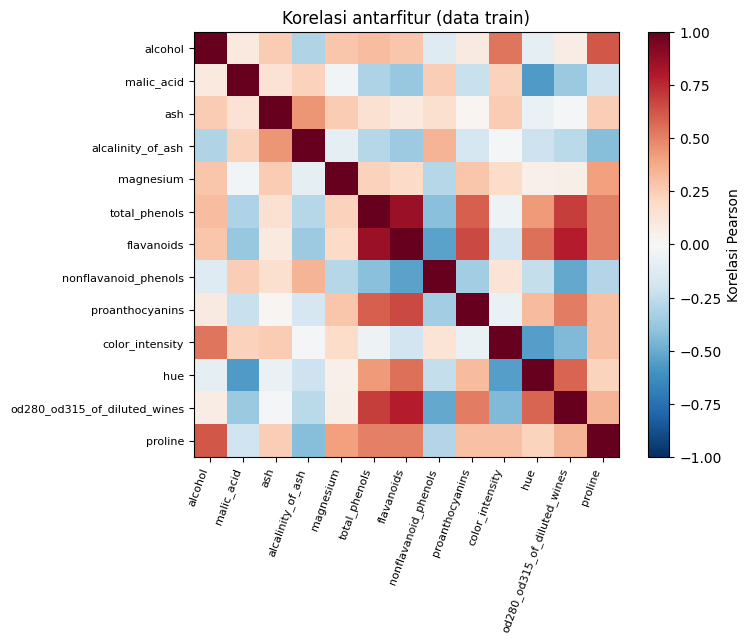

,fitur_1,fitur_2,korelasi
50,total_phenols,flavanoids,0.860927
61,flavanoids,od280_od315_of_diluted_wines,0.786320
55,total_phenols,od280_od315_of_diluted_wines,0.694710
58,flavanoids,proanthocyanins,0.657046
11,alcohol,proline,0.620742


In [8]:
import matplotlib.pyplot as plt, numpy as np
kor = Xtr.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(13), kor.columns, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(13), kor.columns, fontsize=8)
fig.colorbar(im, label="Korelasi Pearson"); ax.set_title("Korelasi antarfitur (data train)")
plt.tight_layout(); plt.show()

pasangan = (kor.where(np.triu(np.ones(kor.shape), 1).astype(bool)).stack()
            .rename("korelasi").reset_index())
pasangan.columns = ["fitur_1", "fitur_2", "korelasi"]
pasangan[pasangan.korelasi.abs() >= 0.6].sort_values("korelasi", key=abs, ascending=False)

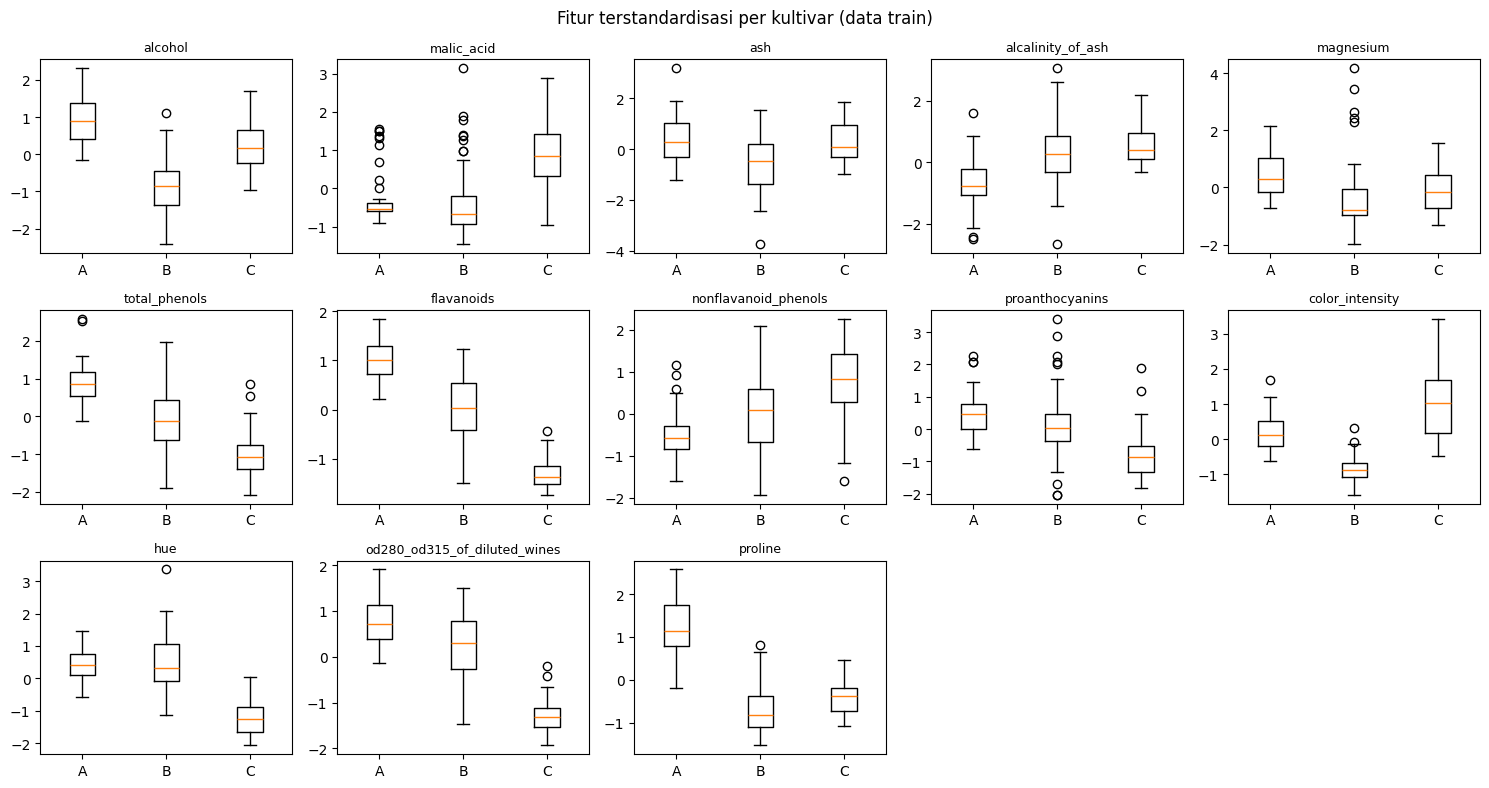

In [9]:
z = (Xtr - Xtr.mean()) / Xtr.std()
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, kol in zip(axes.ravel(), F.FITUR_ASLI):
    data = [z.loc[ytr == k, kol] for k in sorted(ytr.unique())]
    ax.boxplot(data, tick_labels=["A", "B", "C"]); ax.set_title(kol, fontsize=9)
for ax in axes.ravel()[13:]: ax.axis("off")
fig.suptitle("Fitur terstandardisasi per kultivar (data train)"); plt.tight_layout(); plt.show()

## 4. Feature engineering
**Fitur rasio.** Korelasi tertinggi: `total_phenols`–`flavanoids` (0,86), `flavanoids`–`od280/od315` (0,79), dan `total_phenols`–`od280/od315` (0,70). Pasangan yang saling terkait ini dijadikan **rasio** karena rasio menangkap *komposisi* (porsi flavonoid dalam total fenol) yang tidak terlihat pada nilai absolut, dan lebih tahan terhadap perbedaan skala sampel:

| Fitur baru | Rumus | Makna |
|---|---|---|
| `rasio_flavonoid_fenol` | flavanoids / total_phenols | porsi flavonoid dalam fenol |
| `rasio_nonflavonoid_fenol` | nonflavanoid_phenols / total_phenols | porsi fenol nonflavonoid |
| `rasio_proantosianin_fenol` | proanthocyanins / total_phenols | porsi proantosianin |
| `rasio_od_flavonoid` | od280 / flavanoids | absorbansi per flavonoid |
| `rasio_alkalinitas_abu` | alcalinity_of_ash / ash | alkalinitas relatif abu |
| `rasio_prolin_alkohol` | proline / alcohol | prolin relatif alkohol |

Rasio dihitung baris demi baris (*stateless*), sehingga tidak ada kebocoran data.

**Apakah fitur asli dibuang?** Keputusan **tidak ditebak** melainkan diuji dengan CV di data train (ablasi, dijalankan di `latih.py`): varian A (13 asli), B (asli + 6 rasio), C (rasio, tanpa `total_phenols` dan `flavanoids`).

In [10]:
rasio = F.FiturRasio(tambah_rasio=True).fit(Xtr).transform(Xtr)
rasio[list(F.RASIO)].groupby(ytr).mean().round(3)

,rasio_flavonoid_fenol,rasio_nonflavonoid_fenol,rasio_proantosianin_fenol,rasio_od_flavonoid,rasio_alkalinitas_abu,rasio_prolin_alkohol
kultivar,,,,,,
Kultivar A,1.041,0.106,0.668,1.088,6.985,79.654
Kultivar B,0.908,0.176,0.779,1.474,9.147,42.936
Kultivar C,0.471,0.272,0.681,2.559,8.790,47.629


## 5. Pelatihan, perbandingan model, dan evaluasi
`latih.main()` menjalankan: ablasi fitur → *nested CV* untuk 5 algoritma (Logistic Regression, SVM RBF, KNN, Random Forest, Gradient Boosting; tuning di loop dalam) → pelatihan final → evaluasi test **satu kali** → simpan joblib.
Seluruh model berada dalam satu `Pipeline`: `imputasi median → fitur rasio → StandardScaler → model`.

In [11]:
import latih
importlib.reload(latih)
bundle = latih.main()

[data] membaca kasus01_wine.csv dari dataset/
[audit] 178 baris | duplikat=0 | missing=0 | nilai<=0=0
[audit] kelas: {'Kultivar B': 71, 'Kultivar A': 59, 'Kultivar C': 48}
[split] train=142 test=36 (stratified, random_state=42)

[ablasi fitur] F1-macro CV (data train):
                                         varian  Logistic Regression  SVM (RBF)  Random Forest  rata_rata
                        A. Fitur asli saja (13)               0.9815     0.9886         0.9812     0.9838
                           B. Asli + rasio (19)               0.9867     0.9959         0.9767     0.9865
C. Rasio, tanpa total_phenols & flavanoids (17)               0.9891     0.9979         0.9790     0.9887
[ablasi fitur] varian terpilih: C. Rasio, tanpa total_phenols & flavanoids (17)

[nested CV] membandingkan algoritma ...
   Logistic Regression  F1-macro = 0.9859 ± 0.0230
   SVM (RBF)            F1-macro = 1.0000 ± 0.0000
   KNN                  F1-macro = 0.9667 ± 0.0220
   Random Forest        F1-macro

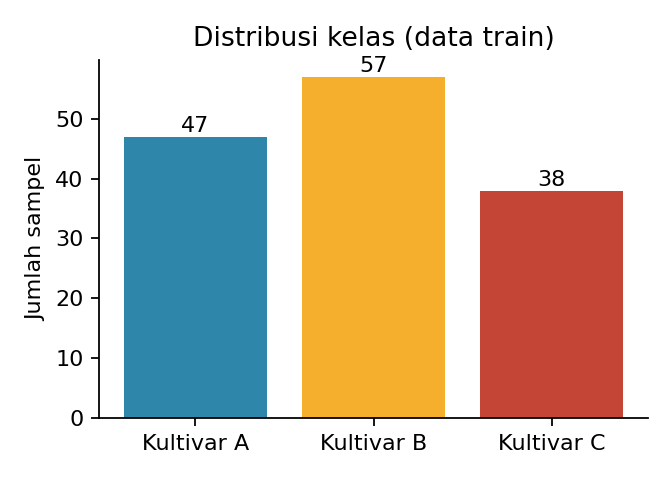

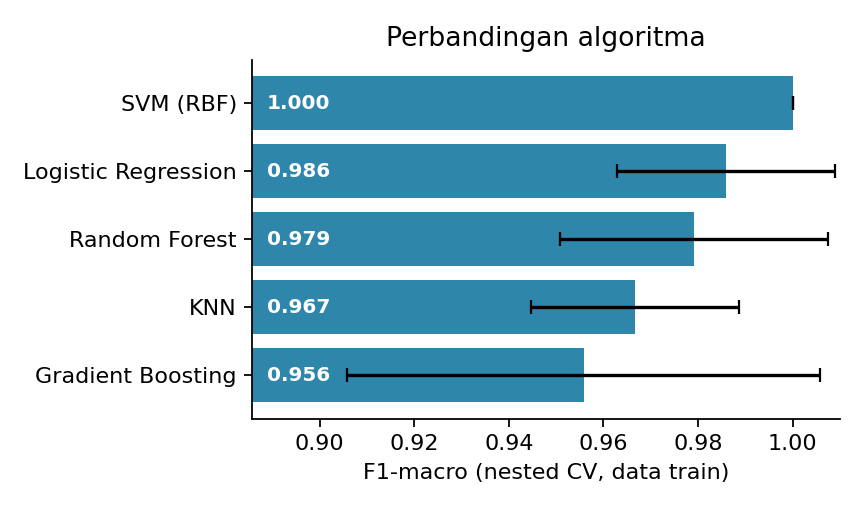

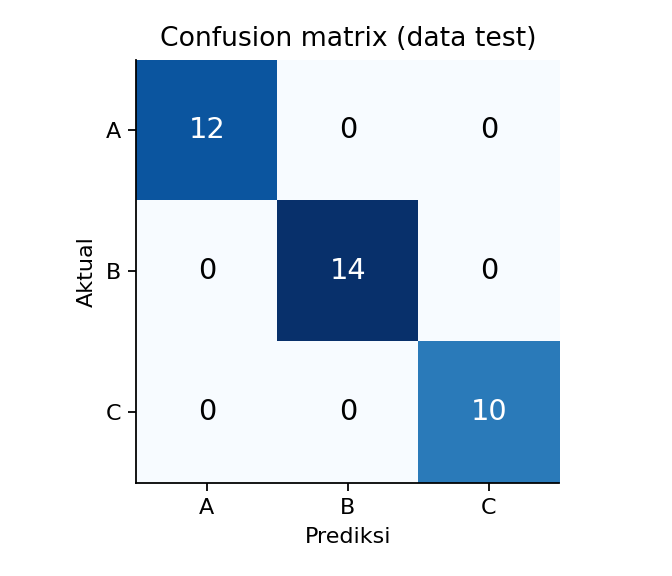

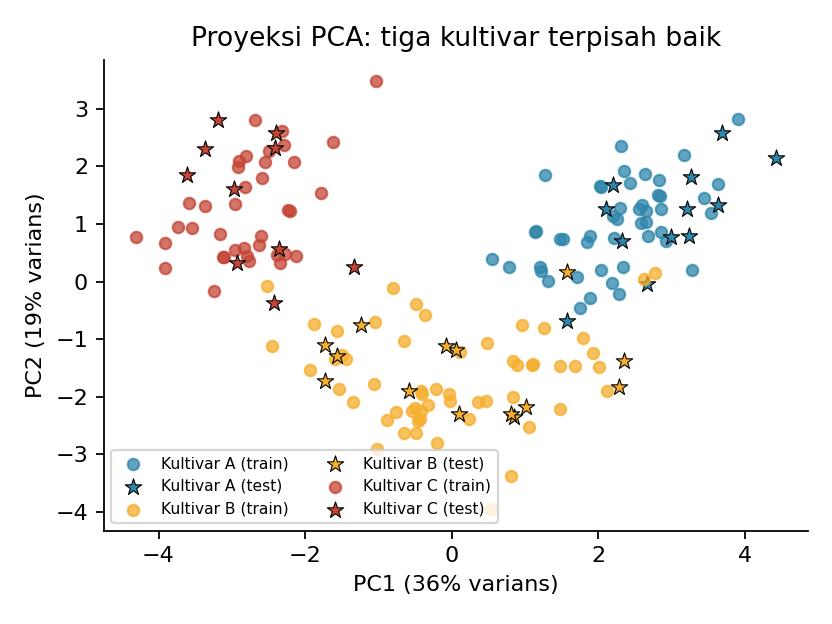

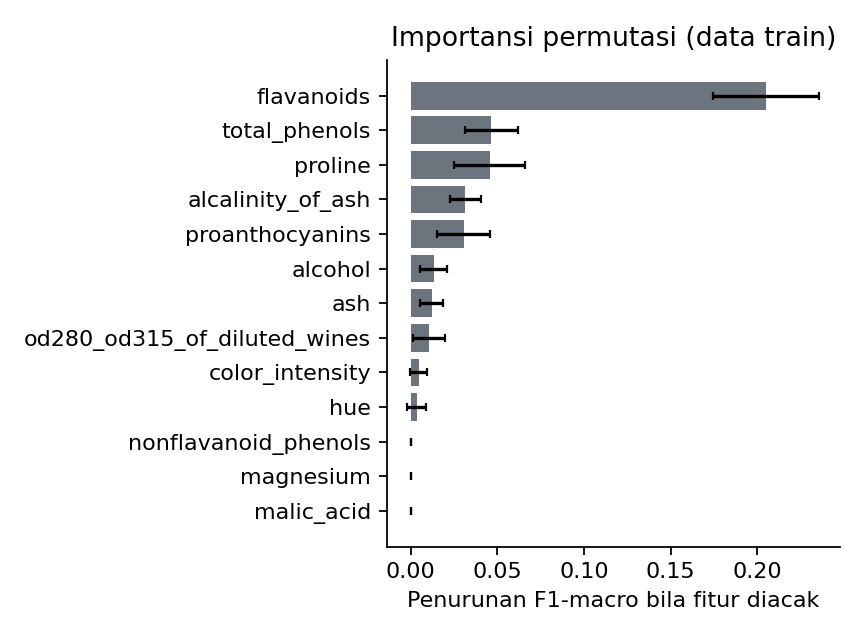

In [12]:
from IPython.display import Image, display
for nama in ["distribusi_kelas", "perbandingan_model", "confusion_matrix", "pca_2d", "importansi"]:
    display(Image(f"models/figures/{nama}.png", width=520))

In [13]:
m = bundle["metrik_test"]
print(f"Model terpilih : {bundle['nama_model']}  {bundle['hyperparameter']}")
print(f"Varian fitur   : {bundle['varian_fitur']}")
ringkas = pd.Series({k: m[k] for k in ["accuracy", "balanced_accuracy", "precision_macro",
                      "recall_macro", "f1_macro", "f1_weighted", "mcc", "log_loss",
                      "roc_auc_ovr_macro", "baseline_akurasi_mayoritas"]}, name="data test").round(4)
display(ringkas.to_frame())
display(pd.DataFrame(m["confusion_matrix"], index=[f"Aktual {k}" for k in bundle["kelas"]],
                     columns=[f"Pred {k}" for k in bundle["kelas"]]))
display(pd.DataFrame(m["laporan_kelas"]).T.round(3))
display(pd.DataFrame(bundle["cv_model"]).round(4))
display(pd.DataFrame(bundle["ablasi_fitur"]).round(4))

Model terpilih : SVM (RBF)  {'model__C': 1.0, 'model__gamma': 'scale'}
Varian fitur   : C. Rasio, tanpa total_phenols & flavanoids (17)


,data test
accuracy,1.0000
balanced_accuracy,1.0000
precision_macro,1.0000
recall_macro,1.0000
f1_macro,1.0000
f1_weighted,1.0000
mcc,1.0000
log_loss,0.0586
roc_auc_ovr_macro,1.0000
baseline_akurasi_mayoritas,0.3889


,Pred Kultivar A,Pred Kultivar B,Pred Kultivar C
Aktual Kultivar A,12,0,0
Aktual Kultivar B,0,14,0
Aktual Kultivar C,0,0,10


,precision,recall,f1-score,support
Kultivar A,1.0,1.0,1.0,12.0
Kultivar B,1.0,1.0,1.0,14.0
Kultivar C,1.0,1.0,1.0,10.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,36.0
weighted avg,1.0,1.0,1.0,36.0


,model,f1_macro_mean,f1_macro_std,accuracy_mean,balanced_accuracy_mean
0,Logistic Regression,0.9859,0.0230,0.9861,0.9886
1,SVM (RBF),1.0000,0.0000,1.0000,1.0000
2,KNN,0.9667,0.0220,0.9648,0.9707
3,Random Forest,0.9791,0.0283,0.9789,0.9820
4,Gradient Boosting,0.9558,0.0500,0.9546,0.9590


,varian,Logistic Regression,SVM (RBF),Random Forest,rata_rata
0,A. Fitur asli saja (13),0.9815,0.9886,0.9812,0.9838
1,B. Asli + rasio (19),0.9867,0.9959,0.9767,0.9865
2,"C. Rasio, tanpa total_phenols & flavanoids (17)",0.9891,0.9979,0.9790,0.9887


## 6. Interpretasi hasil
- **Metrik yang dipakai.** Klasifikasi *multikelas* dengan kelas relatif seimbang: *accuracy* dan *balanced accuracy* dilaporkan, tetapi **F1-macro** dijadikan metrik utama karena memberi bobot sama pada tiap kultivar dan memperhitungkan precision sekaligus recall. *Log loss* dan ROC-AUC (OvR) menilai kualitas probabilitas yang ditampilkan aplikasi; MCC memberi ringkasan tunggal yang ketat untuk multikelas.
- **Perbandingan model.** Angka CV pada sel di atas dihitung dengan nested CV di data train saja; selisih antar model yang kecil perlu dibaca bersama simpangan bakunya.
- **Ablasi fitur.** Varian dengan rata-rata F1-macro CV tertinggi dipilih; selisih antarvarian kecil (di bawah simpangan baku CV), sehingga keputusan ini bersifat ringan dan dilaporkan apa adanya. Importansi permutasi tertinggi ada pada `flavanoids`, `total_phenols`, dan `proline` (pengacakan satu kolom mentah juga merusak rasio turunannya).
- **Peringatan.** Wine adalah dataset yang tergolong mudah dan kecil: test hanya 36 sampel, sehingga akurasi 100% tetap memiliki selang kepercayaan lebar (lihat *accuracy_ci95*). Hasil ini tidak boleh dibaca sebagai jaminan performa pada sampel anggur lain.

## 7. Verifikasi model hasil joblib
Memuat kembali file `.joblib` seperti yang dilakukan aplikasi, lalu memprediksi sampel **mentah**.

In [14]:
import joblib
b = joblib.load("models/wine_kultivar.joblib")
contoh = Xte.head(3)
print("Aktual   :", list(yte.head(3)))
print("Prediksi :", list(b["pipeline"].predict(contoh)))
pd.DataFrame(b["pipeline"].predict_proba(contoh), columns=b["kelas"]).round(3)

Aktual   : ['Kultivar A', 'Kultivar C', 'Kultivar A']
Prediksi : ['Kultivar A', 'Kultivar C', 'Kultivar A']


,Kultivar A,Kultivar B,Kultivar C
0,0.983,0.007,0.010
1,0.023,0.106,0.871
2,0.993,0.003,0.004


## 8. Menjalankan aplikasi Streamlit di Colab
Sel berikut menjalankan `app.py` dan membuka *tunnel* publik (Cloudflare Quick Tunnel, tanpa akun). **Buka tautan `trycloudflare.com` yang dicetak.**
Tautan berlaku selama sel berjalan; jalankan ulang sel untuk membuat tautan baru.

In [15]:
import subprocess, time, re, os, urllib.request
subprocess.run("pkill -f 'streamlit run' ; pkill -f cloudflared", shell=True)
log = open("streamlit.log", "w")
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true",
                  "--browser.gatherUsageStats", "false"], stdout=log, stderr=log)
time.sleep(8)
if not os.path.exists("cloudflared"):
    urllib.request.urlretrieve("https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", "cloudflared")
    os.chmod("cloudflared", 0o755)
tlog = open("tunnel.log", "w")
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"], stdout=tlog, stderr=tlog)
url = None
for _ in range(40):
    time.sleep(2)
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("tunnel.log").read())
    if m:
        url = m.group(0); break
from IPython.display import HTML, display
if url:
    display(HTML(f'<h3>Aplikasi Streamlit: <a href="{url}" target="_blank">{url}</a></h3>'))
else:
    print("Tunnel gagal dibuat. Periksa tunnel.log dan streamlit.log, lalu jalankan ulang sel ini.")

**Cadangan** bila Cloudflare tidak dapat diakses: jalankan `!npm install -q localtunnel` lalu `!npx localtunnel --port 8501` (kata sandi halaman = hasil `!curl -s ipv4.icanhazip.com`).
Aplikasi juga dapat dijalankan lokal dengan `streamlit run app.py`.